# Simulación de Monte carlo: pérdidas de la cartera de tarjetas de crédito


## 1. Librerías y parámetros

In [ ]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV

RANDOM_STATE = 422          
NUM_SIMULACIONES = 10_000
LGD = 0.45                   # pérdida dado el incumplimiento (Es un estándar bancario internacional)

# Opciones de realismo
CALIBRAR_PROBABILIDADES = True    # corrige el inflado de probabilidades por class_weight='balanced'
EXPOSICION_USADA = True           # True: límite x % utilizado | False: límite de crédito completo

## 2. X_train / X_test 

In [ ]:
df = pd.read_csv("clientes_credito_limpios.csv")

df_model = df.drop(columns=['id_cliente', 'nombre', 'incumplimiento_ultimos_6_meses']).copy()

for col in ['ingreso_anual_neto', 'limite_credito']:
    p99 = df_model[col].quantile(0.99)
    df_model[col] = np.where(df_model[col] > p99, p99, df_model[col])

df_model['target'] = (df_model['incumplimiento_tarjeta_credito'] == 'Sí').astype(int)
df_model = df_model.drop(columns=['incumplimiento_tarjeta_credito'])

X = df_model.drop(columns=['target'])
y = df_model['target']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")
print(f"Tasa de incumplimiento en prueba: {y_test.mean()*100:.2f}%")

Entrenamiento: 31869 filas | Prueba: 13659 filas
Tasa de incumplimiento en prueba: 8.12%


## 3. Cargar el modelo y definir el portafolio

In [3]:
artefacto = joblib.load('modelo_incumplimiento_final.joblib') 
pipeline = artefacto['modelo']
nombre_modelo = artefacto['nombre_modelo']
print(f"-> Cargado exitosamente el modelo: {nombre_modelo}")

X_portafolio = X_test.copy()
num_clientes = len(X_portafolio)
print(f"Cargados {num_clientes:,} clientes reales para la simulación.")

# Exposición al incumplimiento (EAD)
if EXPOSICION_USADA:
    exposicion_por_cliente = (X_portafolio['limite_credito'] *
                              X_portafolio['porcentaje_limite_credito_utilizado'] / 100).values
    print("Exposición: límite de crédito x porcentaje utilizado")
else:
    exposicion_por_cliente = X_portafolio['limite_credito'].values
    print("Exposición: límite de crédito completo")

perdida_por_cliente_si_incumple = exposicion_por_cliente * LGD

c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator FunctionTransformer from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unp

-> Cargado exitosamente el modelo: Random Forest
Cargados 13,659 clientes reales para la simulación.
Exposición: límite de crédito x porcentaje utilizado


c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.7.2 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: T

## 4. Probabilidades de incumplimiento (PD)

El Random Forest se entrenó con `class_weight='balanced'`, lo que infla las probabilidades de la clase "incumple". Sirven para clasificar, pero no son PD reales. Si `CALIBRAR_PROBABILIDADES = True`, se calibran con regresión isotónica (validación cruzada de 5 particiones sobre el set de **entrenamiento**, sin tocar el de prueba).

In [4]:
pd_sin_calibrar = pipeline.predict_proba(X_portafolio)[:, 1]

if CALIBRAR_PROBABILIDADES:
    modelo_calibrado = CalibratedClassifierCV(pipeline, method='isotonic', cv=5)
    modelo_calibrado.fit(X_train, y_train)
    pd_individuales = modelo_calibrado.predict_proba(X_portafolio)[:, 1]
else:
    pd_individuales = pd_sin_calibrar

print(f"Tasa real de incumplimiento (test)  : {y_test.mean():.4f}")
print(f"PD promedio sin calibrar            : {pd_sin_calibrar.mean():.4f}")
print(f"PD promedio usada en la simulación  : {pd_individuales.mean():.4f}")

c:\Users\ramonroy\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Tasa real de incumplimiento (test)  : 0.0812
PD promedio sin calibrar            : 0.1478
PD promedio usada en la simulación  : 0.0822


## 5. Simulación de Montecarlo

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
perdidas_totales_escenarios = np.zeros(NUM_SIMULACIONES)

print(f"Ejecutando {NUM_SIMULACIONES:,} simulaciones de Monte carlo...")
for i in range(NUM_SIMULACIONES):
    # Bernoulli: el cliente incumple si el número aleatorio es <= su PD
    incumple = rng.random(num_clientes) <= pd_individuales
    perdidas_totales_escenarios[i] = (incumple * perdida_por_cliente_si_incumple).sum()

perdida_esperada = perdidas_totales_escenarios.mean()
var_95 = np.percentile(perdidas_totales_escenarios, 95)
var_99 = np.percentile(perdidas_totales_escenarios, 99)
perdida_real_observada = (y_test.values * perdida_por_cliente_si_incumple).sum()

print("\n================ RESULTADOS DE RIESGO ================")
print(f"Pérdida Promedio Esperada (EL)  : Q{perdida_esperada:,.2f}")
print(f"Valor en Riesgo al 95% (VaR 95%): Q{var_95:,.2f}")
print(f"Valor en Riesgo al 99% (VaR 99%): Q{var_99:,.2f}")
print(f"Pérdida real observada (test)   : Q{perdida_real_observada:,.2f}")
print("======================================================")

Ejecutando 10,000 simulaciones de Montecarlo...

================ RESULTADOS DE RIESGO ================
Pérdida Promedio Esperada (EL)  : Q17,694,105.09
Valor en Riesgo al 95% (VaR 95%): Q18,139,755.28
Valor en Riesgo al 99% (VaR 99%): Q18,338,808.45
Pérdida real observada (test)   : Q17,731,466.04


## 6. Distribución de pérdidas

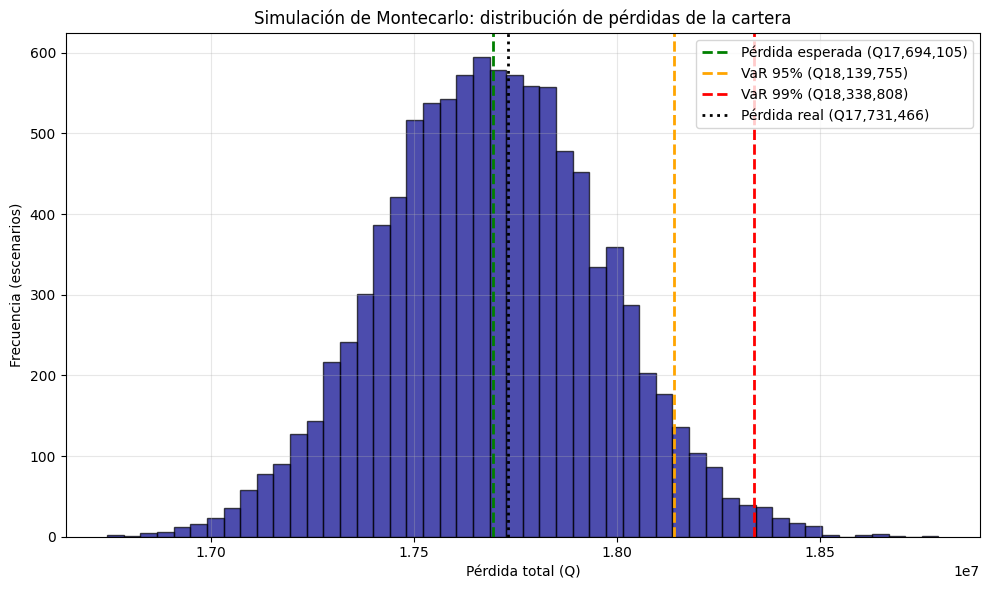

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(perdidas_totales_escenarios, bins=50, color='darkblue', edgecolor='black', alpha=0.7)
plt.axvline(perdida_esperada, color='green', linestyle='--', linewidth=2, label=f'Pérdida esperada (Q{perdida_esperada:,.0f})')
plt.axvline(var_95, color='orange', linestyle='--', linewidth=2, label=f'VaR 95% (Q{var_95:,.0f})')
plt.axvline(var_99, color='red', linestyle='--', linewidth=2, label=f'VaR 99% (Q{var_99:,.0f})')
plt.axvline(perdida_real_observada, color='black', linestyle=':', linewidth=2, label=f'Pérdida real (Q{perdida_real_observada:,.0f})')
plt.title('Simulación de Monte carlo: distribución de pérdidas de la cartera')
plt.xlabel('Pérdida total (Q)')
plt.ylabel('Frecuencia (escenarios)')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> **Limitación:** la simulación supone que los clientes incumplen de forma independiente, por eso el VaR queda muy cerca de la pérdida esperada. En una crisis real los incumplimientos se correlacionan y la cola de pérdidas sería más gruesa.

## 7. Simulación  30 días 

Ejecutando 10,000 simulaciones vectorizadas para 30 días...

================ RESULTADOS DE RIESGO AJUSTADOS A 30 DÍAS ================
Pérdida Promedio Esperada (EL 30d)  : Q10,463,989.73
Valor en Riesgo al 95% (VaR 95% 30d): Q10,832,264.26
Valor en Riesgo al 99% (VaR 99% 30d): Q10,984,426.02
Pérdida Real Teórica (Test 30d)    : Q1,457,380.77


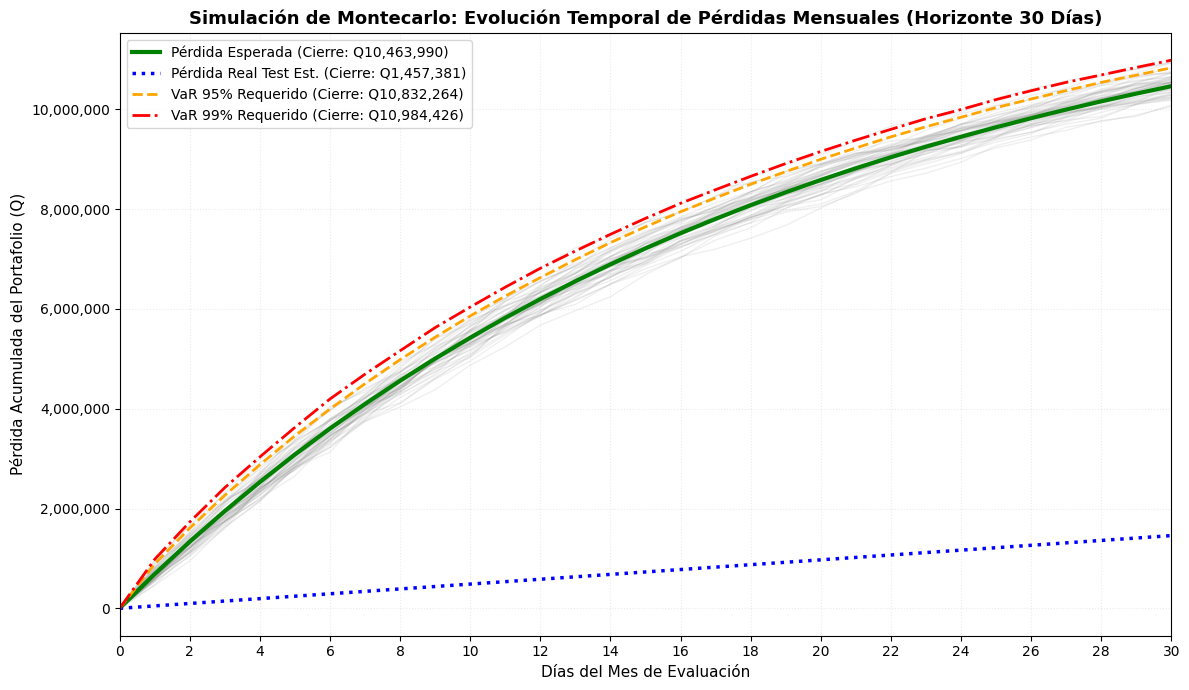

In [ ]:


HORIZONTE_DIAS = 30
PERIODO_ORIGINAL_DIAS = 365 

# Resultados originales de tu notebook para anclaje o referencia
PERDIDA_REAL_TEST_ANUAL = 17731466.04

# 2. Convertir la PD anual a una tasa de falla diaria (Lambda)
eps = 1e-9
tasas_fallas_diarias = -np.log(1 - np.clip(pd_individuales, 0, 1 - eps)) / PERIODO_ORIGINAL_DIAS

# 3. Simulación de Montecarlo con tracking diario (Vectorizado)
rng = np.random.default_rng(RANDOM_STATE)
perdidas_acumuladas_por_dia = np.zeros((NUM_SIMULACIONES, HORIZONTE_DIAS + 1))

print(f"Ejecutando {NUM_SIMULACIONES:,} simulaciones vectorizadas para {HORIZONTE_DIAS} días...")

for i in range(NUM_SIMULACIONES):
    u = rng.random(num_clientes)
    u = np.clip(u, eps, 1.0)
    
    dias_hasta_incumplimiento = -np.log(u) / (tasas_fallas_diarias + 1e-15)
    dia_del_evento = np.ceil(dias_hasta_incumplimiento)
    
    # Filtro seguro para el mes de análisis
    valid_defaults = (dia_del_evento >= 1) & (dia_del_evento <= HORIZONTE_DIAS)
    perdidas_del_mes = np.zeros(HORIZONTE_DIAS + 1)
    
    if np.any(valid_defaults):
        indices_dias = dia_del_evento[valid_defaults].astype(int)
        valores_perdidas = perdida_por_cliente_si_incumple[valid_defaults]
        perdidas_del_mes = np.bincount(indices_dias, weights=valores_perdidas, minlength=HORIZONTE_DIAS + 1)
                
    perdidas_acumuladas_por_dia[i, :] = np.cumsum(perdidas_del_mes)

# 4. Calcular métricas estadísticas diarias
trayectoria_esperada = perdidas_acumuladas_por_dia.mean(axis=0)
trayectoria_var95 = np.percentile(perdidas_acumuladas_por_dia, 95, axis=0)
trayectoria_var99 = np.percentile(perdidas_acumuladas_por_dia, 99, axis=0)

# Línea base de pérdida real mensualizada teórica para comparar en el gráfico
trayectoria_real_test = np.linspace(0, PERDIDA_REAL_TEST_ANUAL * (HORIZONTE_DIAS / PERIODO_ORIGINAL_DIAS), HORIZONTE_DIAS + 1)

print("\n================ RESULTADOS DE RIESGO AJUSTADOS A 30 DÍAS ================")
print(f"Pérdida Promedio Esperada (EL 30d)  : Q{trayectoria_esperada[-1]:,.2f}")
print(f"Valor en Riesgo al 95% (VaR 95% 30d): Q{trayectoria_var95[-1]:,.2f}")
print(f"Valor en Riesgo al 99% (VaR 99% 30d): Q{trayectoria_var99[-1]:,.2f}")
print(f"Pérdida Real Teórica (Test 30d)    : Q{trayectoria_real_test[-1]:,.2f}")
print("==========================================================================")

# 5. GENERACIÓN DEL GRÁFICO DE LÍNEAS
plt.figure(figsize=(12, 7))
dias_eje_x = np.arange(0, HORIZONTE_DIAS + 1)

# Curvas de fondo: Muestra de escenarios volátiles
muestra_escenarios = rng.choice(NUM_SIMULACIONES, size=50, replace=False)
for esc in muestra_escenarios:
    plt.plot(dias_eje_x, perdidas_acumuladas_por_dia[esc, :], color='gray', alpha=0.12, linewidth=1)

# Curvas principales
plt.plot(dias_eje_x, trayectoria_esperada, color='green', linewidth=3, 
         label=f'Pérdida Esperada (Cierre: Q{trayectoria_esperada[-1]:,.0f})')
plt.plot(dias_eje_x, trayectoria_real_test, color='blue', linewidth=2.5, linestyle=':',
         label=f'Pérdida Real Test Est. (Cierre: Q{trayectoria_real_test[-1]:,.0f})')
plt.plot(dias_eje_x, trayectoria_var95, color='orange', linewidth=2, linestyle='--',
         label=f'VaR 95% Requerido (Cierre: Q{trayectoria_var95[-1]:,.0f})')
plt.plot(dias_eje_x, trayectoria_var99, color='red', linewidth=2, linestyle='-.',
         label=f'VaR 99% Requerido (Cierre: Q{trayectoria_var99[-1]:,.0f})')

# Formato estético
plt.title('Simulación de Monte carlo: Evolución Temporal de Pérdidas Mensuales (Horizonte 30 Días)', fontsize=13, fontweight='bold')
plt.xlabel('Días del Mes de Evaluación', fontsize=11)
plt.ylabel('Pérdida Acumulada del Portafolio (Q)', fontsize=11)
plt.xlim(0, HORIZONTE_DIAS)
plt.xticks(np.arange(0, HORIZONTE_DIAS + 1, 2))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.grid(True, alpha=0.25, linestyle=':')
plt.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()
